# Decision Tree Classification/Regression

Develop a decision tree classifier to classify the cost of insurance

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score


In [3]:
# https://www.kaggle.com/datasets/awaiskaggler/insurance-csv
insurance = pd.read_csv('insurance.csv')

# Data exploration

In [6]:
insurance.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
insurance.head()

In [ ]:
insurance.describe()

In [ ]:
# plot numeric values
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Plot boxplot for 'age'
sns.boxplot(ax=axes[0, 0], data=insurance, y='age')
axes[0, 0].set_title('Age')

# Plot boxplot for 'bmi'
sns.boxplot(ax=axes[0, 1], data=insurance, y='bmi')
axes[0, 1].set_title('BMI')

# Plot boxplot for 'children'
sns.boxplot(ax=axes[1, 0], data=insurance, y='children')
axes[1, 0].set_title('Children')

# Plot boxplot for 'charges'
sns.boxplot(ax=axes[1, 1], data=insurance, y='charges')
axes[1, 1].set_title('Charges')

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()

In [ ]:
# distribution of category columns
insurance['region'].value_counts()

In [ ]:
insurance['smoker'].value_counts()

In [ ]:
insurance['sex'].value_counts()

In [ ]:
# distribution of numeric data

In [ ]:
insurance.hist(bins=50, figsize=(12, 8))
plt.show()

In [ ]:
sns.pairplot(insurance[['age', 'bmi', 'children', 'charges']])
plt.show()

In [ ]:
# correlation table 
correlation_table = insurance.corr(numeric_only=True).round(2)
display(correlation_table)

In [ ]:
sns.jointplot(data=insurance, x="age", y="charges")

In [ ]:
sns.jointplot(data=insurance, x="bmi", y="charges")

# Prepare data

The original target, `charges`, is continuous. We convert it into five ordered classes using the 20th, 40th, 60th, and 80th percentiles of the **training target**. The same cutoffs are then applied to the test target. This creates roughly equal-sized training classes without using the test set to choose the boundaries.


In [4]:
# Predict charges using the remaining customer attributes
X = insurance.drop(columns=['charges'])
y_continuous = insurance['charges']

X_train, X_test, y_train_continuous, y_test_continuous = train_test_split(
    X,
    y_continuous,
    test_size=0.30,
    random_state=42,
)

# Define five charge classes using training-set quintiles
quantile_cutoffs = y_train_continuous.quantile([0.2, 0.4, 0.6, 0.8]).to_numpy()
charge_bins = [-np.inf, *quantile_cutoffs, np.inf]
class_labels = ['Very low', 'Low', 'Medium', 'High', 'Extremely high']

y_train = pd.cut(
    y_train_continuous,
    bins=charge_bins,
    labels=class_labels,
    include_lowest=True,
    ordered=True,
)
y_test = pd.cut(
    y_test_continuous,
    bins=charge_bins,
    labels=class_labels,
    include_lowest=True,
    ordered=True,
)

print('Charge cutoffs (calculated from the training set):')
for label, lower, upper in zip(class_labels, charge_bins[:-1], charge_bins[1:]):
    print(f'{label}: {lower:.2f} to {upper:.2f}')

class_counts = pd.DataFrame({
    'Training examples': y_train.value_counts(sort=False),
    'Test examples': y_test.value_counts(sort=False),
})
display(class_counts)

Charge cutoffs (calculated from the training set):
Very low: -inf to 4134.08
Low: 4134.08 to 7443.64
Medium: 7443.64 to 11488.32
High: 11488.32 to 20296.86
Extremely high: 20296.86 to inf


,Training examples,Test examples
charges,,
Very low,188,90
Low,187,77
Medium,187,80
High,187,76
Extremely high,187,79


# Prepare features and train the decision tree

The categorical features are one-hot encoded, while numeric features pass through unchanged. The tree uses entropy (information gain) to select splits. `max_depth` and `min_samples_leaf` limit tree growth to reduce overfitting.

In [5]:
numeric_features = ['age', 'bmi', 'children']
categorical_features = ['sex', 'smoker', 'region']

preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numeric', 'passthrough', numeric_features),
    ]
)

classifier = Pipeline([
    ('preprocessor', preprocessor),
    ('tree', DecisionTreeClassifier(
        criterion='entropy',
        max_depth=5,
        min_samples_leaf=10,
        random_state=42,
    )),
])

classifier.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('tree', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['Extremely high','High','Low','Medium','Very low']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

# Visualise the decision tree

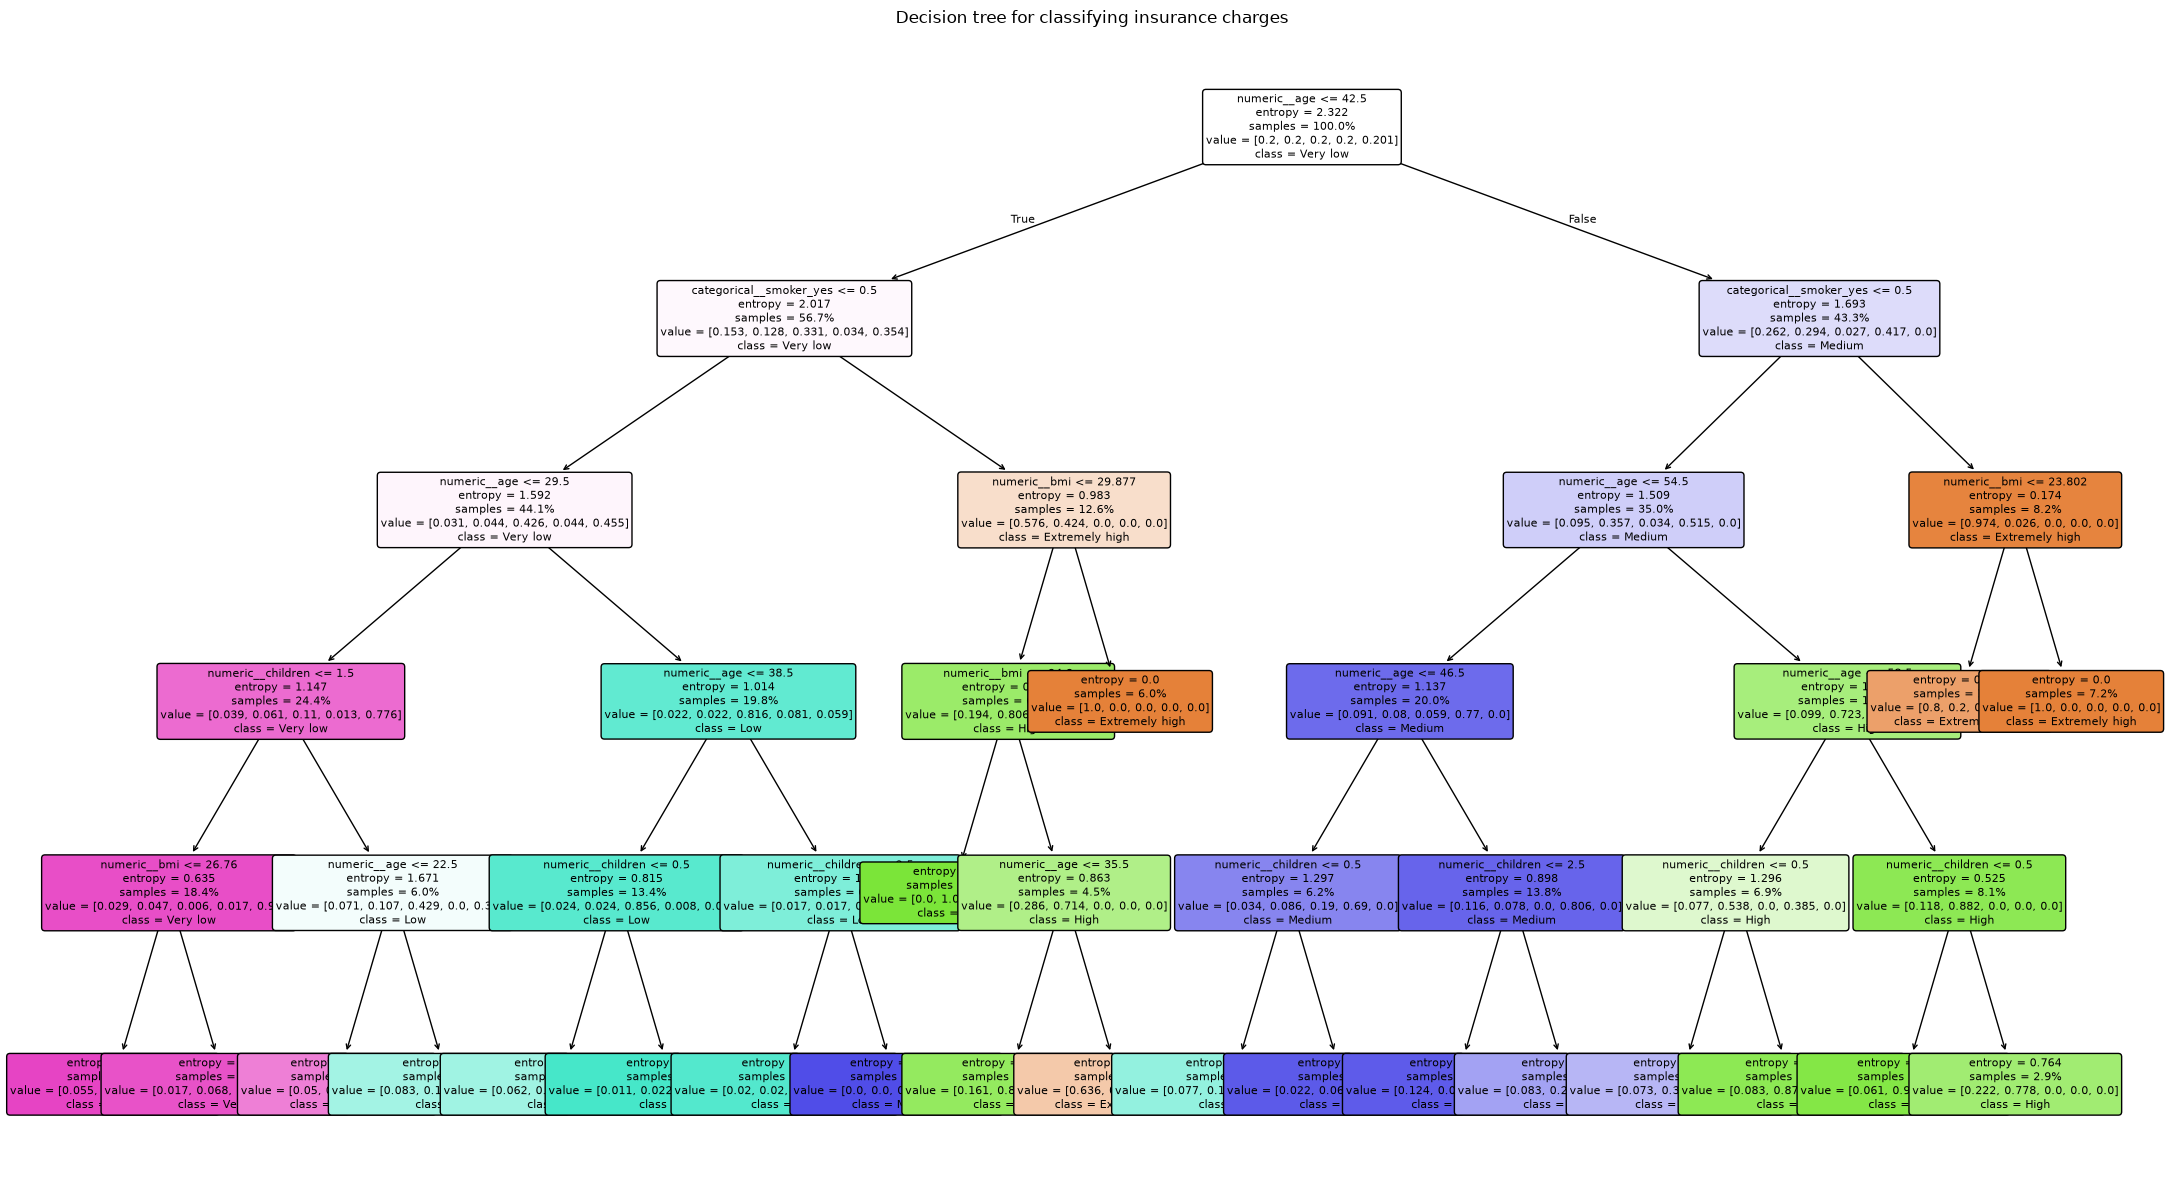

In [11]:
feature_names = classifier.named_steps['preprocessor'].get_feature_names_out()
class_names = classifier.named_steps['tree'].classes_

plt.figure(figsize=(22, 12))
plot_tree(
    classifier.named_steps['tree'],
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    proportion=True,
    impurity=True,
    fontsize=8,
)
plt.title('Decision tree for classifying insurance charges')
plt.tight_layout()
plt.savefig("decision_tree.png", dpi=300, bbox_inches="tight")
plt.show()

# Evaluate with stratified 5-fold cross-validation

Accuracy reports the proportion of correct predictions. Macro precision, recall, and F1 calculate each metric separately for the five classes and then average the results, giving each class equal weight. Comparing training and validation scores can help reveal overfitting.

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'Accuracy': 'accuracy',
    'Precision (macro)': 'precision_macro',
    'Recall (macro)': 'recall_macro',
    'F1 (macro)': 'f1_macro',
}

cv_scores = cross_validate(
    classifier,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
)

cv_summary = pd.DataFrame({
    'Metric': list(scoring),
    'Mean training score': [cv_scores[f'train_{metric}'].mean() for metric in scoring],
    'Mean validation score': [cv_scores[f'test_{metric}'].mean() for metric in scoring],
    'Validation standard deviation': [cv_scores[f'test_{metric}'].std() for metric in scoring],
})
display(cv_summary.round(3))

,Metric,Mean training score,Mean validation score,Validation standard deviation
0,Accuracy,0.836,0.814,0.023
1,Precision (macro),0.848,0.828,0.025
2,Recall (macro),0.836,0.814,0.023
3,F1 (macro),0.835,0.813,0.025


# Evaluate once on the held-out test set

Classification report on the test set:
                precision    recall  f1-score   support

      Very low       0.89      0.86      0.87        90
           Low       0.72      0.90      0.80        77
        Medium       0.73      0.90      0.80        80
          High       0.89      0.66      0.76        76
Extremely high       0.98      0.80      0.88        79

      accuracy                           0.82       402
     macro avg       0.84      0.82      0.82       402
  weighted avg       0.84      0.82      0.82       402



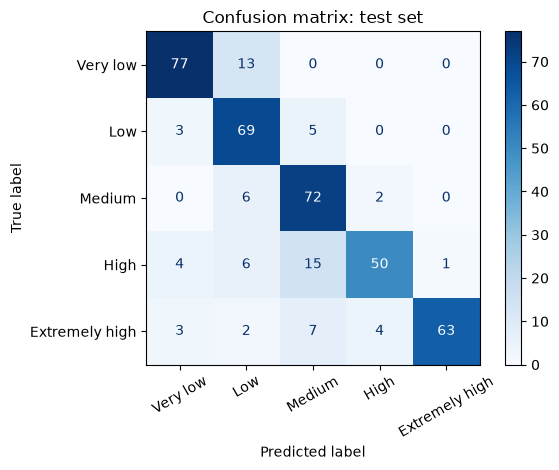

In [9]:
y_pred = classifier.predict(X_test)

print('Classification report on the test set:')
print(classification_report(
    y_test,
    y_pred,
    labels=class_labels,
    target_names=class_labels,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=class_labels,
    display_labels=class_labels,
    cmap='Blues',
    values_format='d',
    xticks_rotation=30,
)
plt.title('Confusion matrix: test set')
plt.tight_layout()
plt.show()

# Inspect feature importance

In [10]:
importance = pd.Series(
    classifier.named_steps['tree'].feature_importances_,
    index=feature_names,
    name='Importance',
).sort_values(ascending=False)

display(importance.to_frame().round(3))

,Importance
numeric__age,0.543
categorical__smoker_yes,0.305
numeric__children,0.092
numeric__bmi,0.060
categorical__sex_female,0.000
categorical__sex_male,0.000
categorical__smoker_no,0.000
categorical__region_northeast,0.000
categorical__region_northwest,0.000
categorical__region_southeast,0.000


# Random Forest Classification

Each tree is trained on a bootstrap sample, and the trees consider random subsets of features when splitting. For classification, their predictions are combined by voting.

In [12]:
from sklearn.ensemble import RandomForestClassifier

rf_preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('numeric', 'passthrough', numeric_features),
    ]
)

random_forest = Pipeline([
    ('preprocessor', rf_preprocessor),
    ('forest', RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1,
    )),
])

random_forest.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](5,)","['Extremely high','High','Low','Medium','Very low']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['age','sex','bmi','children','smoker','region']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifyin

# Evaluate with stratified 5-fold cross-validation

In [13]:
rf_cv_scores = cross_validate(
    random_forest,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    return_train_score=True,
)

rf_cv_summary = pd.DataFrame({
    'Metric': list(scoring),
    'Mean training score': [rf_cv_scores[f'train_{metric}'].mean() for metric in scoring],
    'Mean validation score': [rf_cv_scores[f'test_{metric}'].mean() for metric in scoring],
    'Validation standard deviation': [rf_cv_scores[f'test_{metric}'].std() for metric in scoring],
})
display(rf_cv_summary.round(3))

,Metric,Mean training score,Mean validation score,Validation standard deviation
0,Accuracy,0.938,0.854,0.016
1,Precision (macro),0.941,0.865,0.013
2,Recall (macro),0.938,0.853,0.016
3,F1 (macro),0.937,0.852,0.017


# Evaluate the random forest on test set

Random forest classification report on the test set:
                precision    recall  f1-score   support

      Very low       0.87      0.91      0.89        90
           Low       0.75      0.87      0.81        77
        Medium       0.77      0.90      0.83        80
          High       0.90      0.75      0.82        76
Extremely high       1.00      0.80      0.89        79

      accuracy                           0.85       402
     macro avg       0.86      0.85      0.85       402
  weighted avg       0.86      0.85      0.85       402



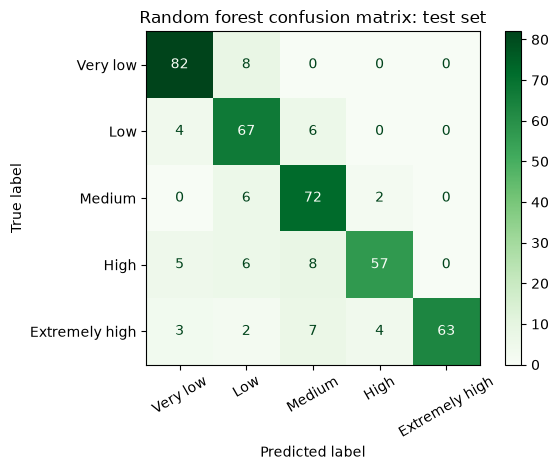

In [14]:
rf_y_pred = random_forest.predict(X_test)

print('Random forest classification report on the test set:')
print(classification_report(
    y_test,
    rf_y_pred,
    labels=class_labels,
    target_names=class_labels,
    zero_division=0,
))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    rf_y_pred,
    labels=class_labels,
    display_labels=class_labels,
    cmap='Greens',
    values_format='d',
    xticks_rotation=30,
)
plt.title('Random forest confusion matrix: test set')
plt.tight_layout()
plt.show()

# Inspect random forest feature importance

In [16]:
rf_feature_names = random_forest.named_steps['preprocessor'].get_feature_names_out()
rf_importance = pd.Series(
    random_forest.named_steps['forest'].feature_importances_,
    index=rf_feature_names,
    name='Importance',
).sort_values(ascending=False)

display(rf_importance.to_frame().round(3))

,Importance
numeric__age,0.503
numeric__bmi,0.152
categorical__smoker_no,0.109
categorical__smoker_yes,0.087
numeric__children,0.083
categorical__region_northeast,0.012
categorical__region_southeast,0.012
categorical__sex_male,0.011
categorical__sex_female,0.011
categorical__region_southwest,0.010


# compare the peformance of decision tree and random forest

In [19]:
models = {
    "Decision Tree": classifier,
    "Random Forest": random_forest,
}

comparison_scoring = {
    "accuracy": "accuracy",
    "macro_precision": "precision_macro",
    "macro_recall": "recall_macro",
    "macro_f1": "f1_macro",
}

results = []

for name, model in models.items():
    # Cross-validation on the training set
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=comparison_scoring,
    )

    # Evaluation on the same held-out test set
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "CV accuracy": cv_scores["test_accuracy"].mean(),
        "CV macro F1": cv_scores["test_macro_f1"].mean(),
        "Test accuracy": accuracy_score(y_test, y_pred),
        "Test macro precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Test macro recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Test macro F1": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
    })

comparison = pd.DataFrame(results).set_index("Model")
display(comparison.round(3))

,CV accuracy,CV macro F1,Test accuracy,Test macro precision,Test macro recall,Test macro F1
Model,,,,,,
Decision Tree,0.814,0.813,0.823,0.842,0.821,0.822
Random Forest,0.854,0.852,0.848,0.861,0.846,0.848
